# Hammernik Variational Network across acceleration rates

This notebook reports the completed **50-pass / 9,700-update** supervised
experiments currently available at **2×, 4×, 6×**. For each rate, ten checkpoints
were screened on validation data, and the selected checkpoint was evaluated once on
the same 14-volume held-out test split.

The implementation preserves the published 10-stage architecture, complex 11×11
filters, Gaussian-RBF influence functions, learned SENSE data weights, filter
constraints, and three-block iPALM optimizer. TensorFlow/custom operators were
ported to native PyTorch, and the data protocol uses this project's brain cohort,
supplied maps, and frozen Cartesian masks.

References: [paper](https://doi.org/10.1002/mrm.26977) ·
[official repository](https://github.com/VLOGroup/mri-variationalnetwork)

In [1]:
from pathlib import Path
from html import escape
import json, os, re
import matplotlib.pyplot as plt
import numpy as np
from IPython.display import HTML, Image, display

ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
DERIVED = Path('/data/david_agyei/nyu-dataset/derived')
RUNS = {rate: DERIVED/f'hammernik_variational_network_{rate}x_ipalm'
        for rate in (2, 4, 6, 8)
        if (DERIVED/f'hammernik_variational_network_{rate}x_ipalm/evaluation/best_validation_checkpoint.json').exists()}
RATES = tuple(sorted(RUNS))
RUN = Path(os.environ.get('VN_CHECKPOINT_DIR', RUNS[4]))
EVAL = RUN / 'evaluation'

def read_json(path): return json.loads(Path(path).read_text())
def selected_test(run):
    evaluation = Path(run) / 'evaluation'
    selected = read_json(evaluation / 'best_validation_checkpoint.json')
    return read_json(evaluation / 'test' / f"step-{selected['checkpoint_step']:07d}" / 'summary.json')
def show_table(rows, columns, precision=4, bold_best=None, bold_pairs=None):
    bold_best = bold_best or {}
    bold_pairs = bold_pairs or []
    best = {}
    for key, direction in bold_best.items():
        values = [row[key] for row in rows if isinstance(row[key], (int, float)) and np.isfinite(row[key])]
        best[key] = (max if direction == 'max' else min)(values)
    def render(value): return f'{value:.{precision}f}' if isinstance(value, float) else escape(str(value))
    header = ''.join(f'<th style="text-align:left;padding:4px 10px">{escape(label)}</th>' for key, label in columns)
    bold_cells = set()
    for left, right, direction in bold_pairs:
        for index, row in enumerate(rows):
            pair = [row[left], row[right]]
            pair_best = (max if direction == 'max' else min)(pair)
            if np.isclose(row[left], pair_best): bold_cells.add((index, left))
            if np.isclose(row[right], pair_best): bold_cells.add((index, right))
    def cell(row, key, index):
        value = render(row[key])
        if ((key in best and np.isclose(row[key], best[key])) or
                (index, key) in bold_cells):
            value = f'<strong>{value}</strong>'
        return f'<td style="padding:4px 10px">{value}</td>'
    body = ''.join('<tr>' + ''.join(cell(row, key, index) for key, label in columns) + '</tr>'
                   for index, row in enumerate(rows))
    display(HTML(f'<table><thead><tr>{header}</tr></thead><tbody>{body}</tbody></table>'))

selection = read_json(EVAL / 'best_validation_checkpoint.json')
step = selection['checkpoint_step']
test_dir = EVAL / 'test' / f'step-{step:07d}'
test = read_json(test_dir / 'summary.json')
progression = read_json(ROOT / 'results/variational_network_evaluation/qualitative/stage_progression.json')
print(f"Selected epoch {selection['completed_epochs']}, step {step:,}")
print('Available completed rates:', ', '.join(f'{rate}×' for rate in RATES))

Selected epoch 25, step 4,850
Available completed rates: 2×, 4×, 6×


## Training trajectory

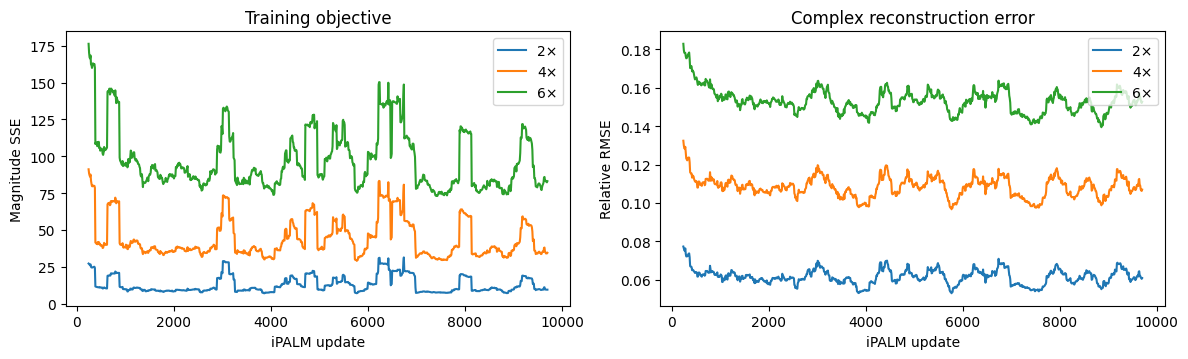

Lines are 25-record moving averages of the logged training minibatches.


In [2]:
pattern = re.compile(
    r'iteration=(\d+)/\d+ step=(\d+).*?loss=([0-9.eE+-]+) '
    r'magnitude_mse=([0-9.eE+-]+) relative_rmse=([0-9.eE+-]+) '
    r'data_weight=([0-9.eE+-]+) gradient_norm=([0-9.eE+-]+)'
)
window = 25
def smooth(values): return np.convolve(values, np.ones(window)/window, mode='valid')
fig, axes = plt.subplots(1, 2, figsize=(12, 3.7))
for rate in RATES:
    records = [match.groups() for line in (RUNS[rate]/'train.log').read_text().splitlines()
               if (match := pattern.search(line))]
    records = list({int(row[1]): row for row in records}.values())
    records.sort(key=lambda row: int(row[1]))
    steps = np.array([int(row[1]) for row in records])
    loss = np.array([float(row[2]) for row in records])
    relative_rmse = np.array([float(row[4]) for row in records])
    axes[0].plot(steps[window-1:], smooth(loss), label=f'{rate}×')
    axes[1].plot(steps[window-1:], smooth(relative_rmse), label=f'{rate}×')
axes[0].set(xlabel='iPALM update', ylabel='Magnitude SSE', title='Training objective')
axes[1].set(xlabel='iPALM update', ylabel='Relative RMSE', title='Complex reconstruction error')
axes[0].legend(); axes[1].legend()
plt.tight_layout(); plt.show()
print('Lines are 25-record moving averages of the logged training minibatches.')

## Cross-rate validation selection and held-out test results

Rate,Selected epoch,ZF PSNR,VarNet PSNR,ZF SSIM,VarNet SSIM,ZF NMSE,VarNet NMSE,Seconds/slice
2×,25,35.9877,41.9284,0.9304,0.9674,0.0179,0.0102,0.0264
4×,25,29.7164,36.2104,0.8295,0.9165,0.0631,0.0358,0.0370
6×,40,26.8159,32.4079,0.7736,0.8664,0.1066,0.0571,0.0269


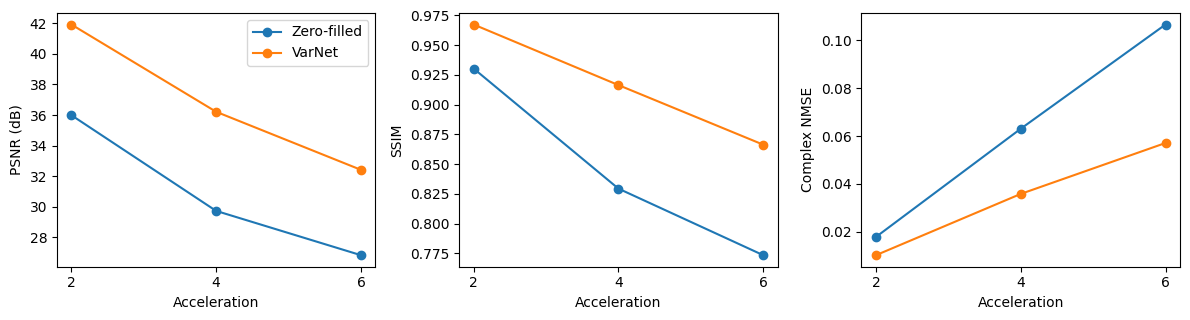

In [3]:
rate_selections = {rate: read_json(RUNS[rate]/'evaluation/best_validation_checkpoint.json')
                   for rate in RATES}
rate_tests = {
    rate: read_json(
        RUNS[rate]/'evaluation/test'/
        f"step-{rate_selections[rate]['checkpoint_step']:07d}"/'summary.json'
    )
    for rate in RATES
}
rate_rows = []
for rate in RATES:
    selected = rate_selections[rate]
    summary = rate_tests[rate]
    baseline, result = summary['zero_filled'], summary['variational_network']
    rate_rows.append({
        'Rate': f'{rate}×', 'Selected epoch': selected['completed_epochs'],
        'ZF PSNR': baseline['psnr'], 'VarNet PSNR': result['psnr'],
        'ZF SSIM': baseline['ssim'], 'VarNet SSIM': result['ssim'],
        'ZF NMSE': baseline['nmse'], 'VarNet NMSE': result['nmse'],
        'Seconds/slice': result['seconds_per_slice'],
    })
show_table(rate_rows, [(key, key) for key in rate_rows[0]], bold_pairs=[
    ('ZF PSNR', 'VarNet PSNR', 'max'), ('ZF SSIM', 'VarNet SSIM', 'max'),
    ('ZF NMSE', 'VarNet NMSE', 'min')])

fig, axes = plt.subplots(1, 3, figsize=(12, 3.3))
x = np.array(RATES)
for axis, metric, label in zip(axes, ['psnr', 'ssim', 'nmse'],
                               ['PSNR (dB)', 'SSIM', 'Complex NMSE']):
    axis.plot(x, [rate_tests[r]['zero_filled'][metric] for r in RATES], marker='o', label='Zero-filled')
    axis.plot(x, [rate_tests[r]['variational_network'][metric] for r in RATES], marker='o', label='VarNet')
    axis.set(xlabel='Acceleration', ylabel=label, xticks=x)
axes[0].legend()
plt.tight_layout(); plt.show()

## Validation checkpoint selection by rate

Rate,Epoch,Step,PSNR,SSIM,NMSE,Residual
2×,25,4850,42.3998,0.9737,0.0033,0.1912
4×,25,4850,36.7219,0.9298,0.0105,0.1404
6×,40,7760,33.3178,0.8848,0.0219,0.1209


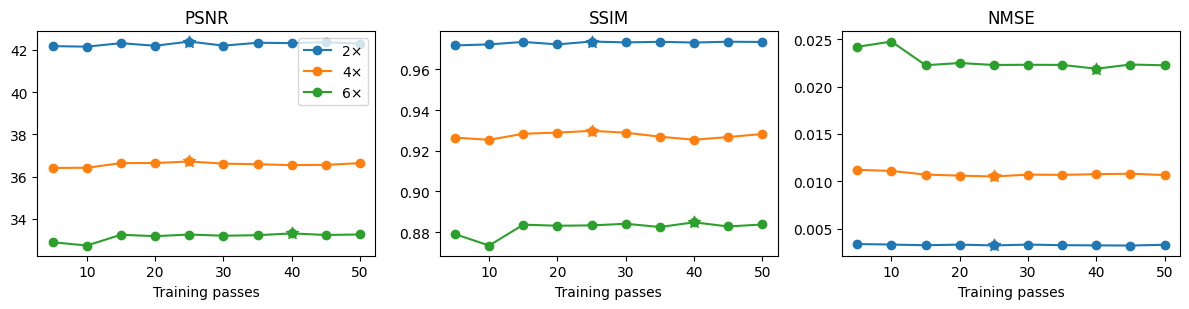

Stars mark the maximum volume-averaged validation-PSNR checkpoint for each rate.


In [4]:
selected_rows = []
for rate in RATES:
    selected = rate_selections[rate]
    selected_rows.append({
        'Rate': f'{rate}×', 'Epoch': selected['completed_epochs'],
        'Step': selected['checkpoint_step'],
        'PSNR': selected['validation_metrics']['psnr'],
        'SSIM': selected['validation_metrics']['ssim'],
        'NMSE': selected['validation_metrics']['nmse'],
        'Residual': selected['validation_metrics']['measurement_residual'],
    })
show_table(selected_rows, [(key, key) for key in selected_rows[0]])

fig, axes = plt.subplots(1, 3, figsize=(12, 3.2))
for rate in RATES:
    validation = [{'Epoch': row['completed_epochs'],
                   'PSNR': row['variational_network']['psnr'],
                   'SSIM': row['variational_network']['ssim'],
                   'NMSE': row['variational_network']['nmse']}
                  for row in rate_selections[rate]['candidates']]
    for axis, metric in zip(axes, ['PSNR', 'SSIM', 'NMSE']):
        axis.plot([row['Epoch'] for row in validation], [row[metric] for row in validation],
                  marker='o', label=f'{rate}×')
        chosen = next(row for row in validation
                      if row['Epoch'] == rate_selections[rate]['completed_epochs'])
        axis.scatter([chosen['Epoch']], [chosen[metric]], marker='*', s=80)
        axis.set(xlabel='Training passes', title=metric)
axes[0].legend()
plt.tight_layout(); plt.show()
print('Stars mark the maximum volume-averaged validation-PSNR checkpoint for each rate.')

## Held-out comparison with completed supervised models

In [5]:
def sole_test(root):
    paths = sorted((Path(root)/'evaluation/test').glob('step-*/summary.json'))
    if not paths: raise RuntimeError(f'no test summary under {root}')
    summaries = [read_json(path) for path in paths]
    return max(summaries, key=lambda item: int(item['checkpoint_step']))

rdbm_roots = {
    2: DERIVED/'rdbm_2x_bf16', 4: DERIVED/'rdbm_full_bf16',
    6: DERIVED/'rdbm_6x_bf16', 8: DERIVED/'rdbm_8x_bf16'}
for rate in RATES:
    modl = sole_test(DERIVED/f'modl_{rate}x_fp32')
    cascade = sole_test(DERIVED/f'multicoil_cascade_cnn_{rate}x')
    rdbm = sole_test(rdbm_roots[rate])
    unrolled = sole_test(DERIVED/f'full_diffusion_unrolled_rdbm_{rate}x_scratch')
    models = [
        ('Zero-filled', rate_tests[rate]['zero_filled']),
        ('MoDL', modl['modl']),
        ('Cascade CNN', cascade['cascade_cnn']),
        ('RDBM', rdbm['rdbm']),
        ('Full diffusion-unrolled RDBM', unrolled['diffusion_unrolled_rdbm']),
        ('Variational Network', rate_tests[rate]['variational_network']),
    ]
    comparison = [{'Method': name, 'PSNR ↑': values['psnr'], 'SSIM ↑': values['ssim'],
                   'Complex NMSE ↓': values['nmse'],
                   'Residual ↓': values['measurement_residual'],
                   'Seconds/slice ↓': values.get('seconds_per_slice', np.nan)}
                  for name, values in models]
    print(f'{rate}× acceleration')
    show_table(comparison, [(key, key) for key in comparison[0]],
               bold_best={'PSNR ↑':'max', 'SSIM ↑':'max', 'Complex NMSE ↓':'min',
                          'Residual ↓':'min', 'Seconds/slice ↓':'min'})

2× acceleration


Method,PSNR ↑,SSIM ↑,Complex NMSE ↓,Residual ↓,Seconds/slice ↓
Zero-filled,35.9877,0.9304,0.0179,0.2021,nan
MoDL,39.6646,0.8305,0.0257,0.1970,0.0570
Cascade CNN,40.1660,0.9538,0.0162,0.1959,0.0381
RDBM,40.8276,0.9586,0.0199,0.1954,0.1933
Full diffusion-unrolled RDBM,40.3589,0.9445,0.0138,0.1965,0.3984
Variational Network,41.9284,0.9674,0.0102,0.1965,0.0264


4× acceleration


Method,PSNR ↑,SSIM ↑,Complex NMSE ↓,Residual ↓,Seconds/slice ↓
Zero-filled,29.7164,0.8295,0.0631,0.1622,nan
MoDL,34.8049,0.8024,0.1104,0.1474,0.0538
Cascade CNN,35.2762,0.9080,0.0422,0.1454,0.1501
RDBM,35.6007,0.9207,0.0559,0.1450,0.1916
Full diffusion-unrolled RDBM,36.7149,0.9088,0.0378,0.1478,0.3989
Variational Network,36.2104,0.9165,0.0358,0.1467,0.0370


6× acceleration


Method,PSNR ↑,SSIM ↑,Complex NMSE ↓,Residual ↓,Seconds/slice ↓
Zero-filled,26.8159,0.7736,0.1066,0.1542,nan
MoDL,30.8370,0.7660,0.1588,0.1306,0.0557
Cascade CNN,32.0217,0.8703,0.0622,0.1279,0.0384
RDBM,32.1543,0.8825,0.0811,0.1277,0.1907
Full diffusion-unrolled RDBM,34.1697,0.8839,0.0488,0.1293,0.4745
Variational Network,32.4079,0.8664,0.0571,0.1308,0.0269


## Results by acquisition and acceleration

In [6]:
acquisition = []
for rate in RATES:
    for name, group in rate_tests[rate]['by_acquisition'].items():
        acquisition.append({'Rate': f'{rate}×', 'Acquisition': name,
            'Volumes': group['volume_count'],
            'ZF PSNR': group['zero_filled']['psnr'], 'VarNet PSNR': group['variational_network']['psnr'],
            'ZF SSIM': group['zero_filled']['ssim'], 'VarNet SSIM': group['variational_network']['ssim'],
            'ZF NMSE': group['zero_filled']['nmse'], 'VarNet NMSE': group['variational_network']['nmse']})
show_table(acquisition, [(key, key) for key in acquisition[0]], bold_pairs=[
    ('ZF PSNR', 'VarNet PSNR', 'max'), ('ZF SSIM', 'VarNet SSIM', 'max'),
    ('ZF NMSE', 'VarNet NMSE', 'min')])

Rate,Acquisition,Volumes,ZF PSNR,VarNet PSNR,ZF SSIM,VarNet SSIM,ZF NMSE,VarNet NMSE
2×,AXFLAIR,2,32.8875,37.2386,0.8978,0.9329,0.0482,0.0459
2×,AXT1POST,10,36.5251,42.7578,0.9339,0.9728,0.0125,0.0043
2×,AXT1PRE,2,36.4010,42.4711,0.9453,0.9752,0.0142,0.0045
4×,AXFLAIR,2,28.5068,32.8211,0.7856,0.8527,0.1230,0.1738
4×,AXT1POST,10,29.9895,36.6957,0.8333,0.9257,0.0512,0.0127
4×,AXT1PRE,2,29.5610,37.1732,0.8545,0.9342,0.0627,0.0138
6×,AXFLAIR,2,25.8789,29.5190,0.7208,0.8051,0.1690,0.2155
6×,AXT1POST,10,27.2000,33.3323,0.7832,0.8828,0.0882,0.0254
6×,AXT1PRE,2,25.8325,30.6746,0.7782,0.8461,0.1366,0.0574


## Learned physics weights across rates

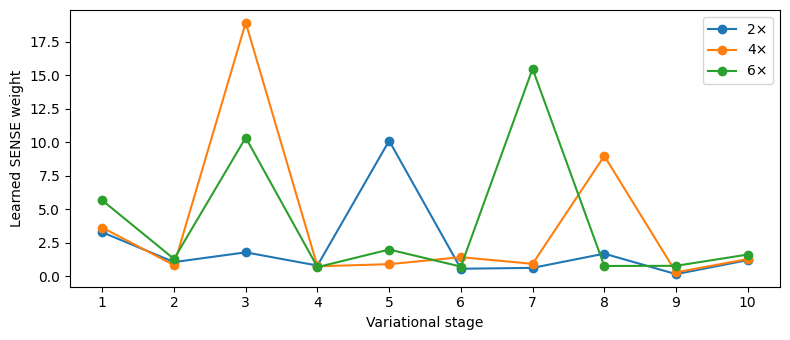

In [7]:
plt.figure(figsize=(8, 3.5))
for rate in RATES:
    weights = np.array(rate_tests[rate]['data_term_weights'])
    plt.plot(np.arange(1, len(weights)+1), weights, marker='o', label=f'{rate}×')
plt.xlabel('Variational stage'); plt.ylabel('Learned SENSE weight'); plt.xticks(np.arange(1, 11))
plt.legend()
plt.tight_layout(); plt.show()

## Representative 4× stage progression

The progression figure remains the matched 4× qualitative example. The quantitative
training, validation, test, acquisition, and learned-weight analyses above cover every
completed acceleration rate equally.

Representative sample: file_brain_AXT1POST_209_6001292:7 (test slice closest to median VarNet PSNR gain)


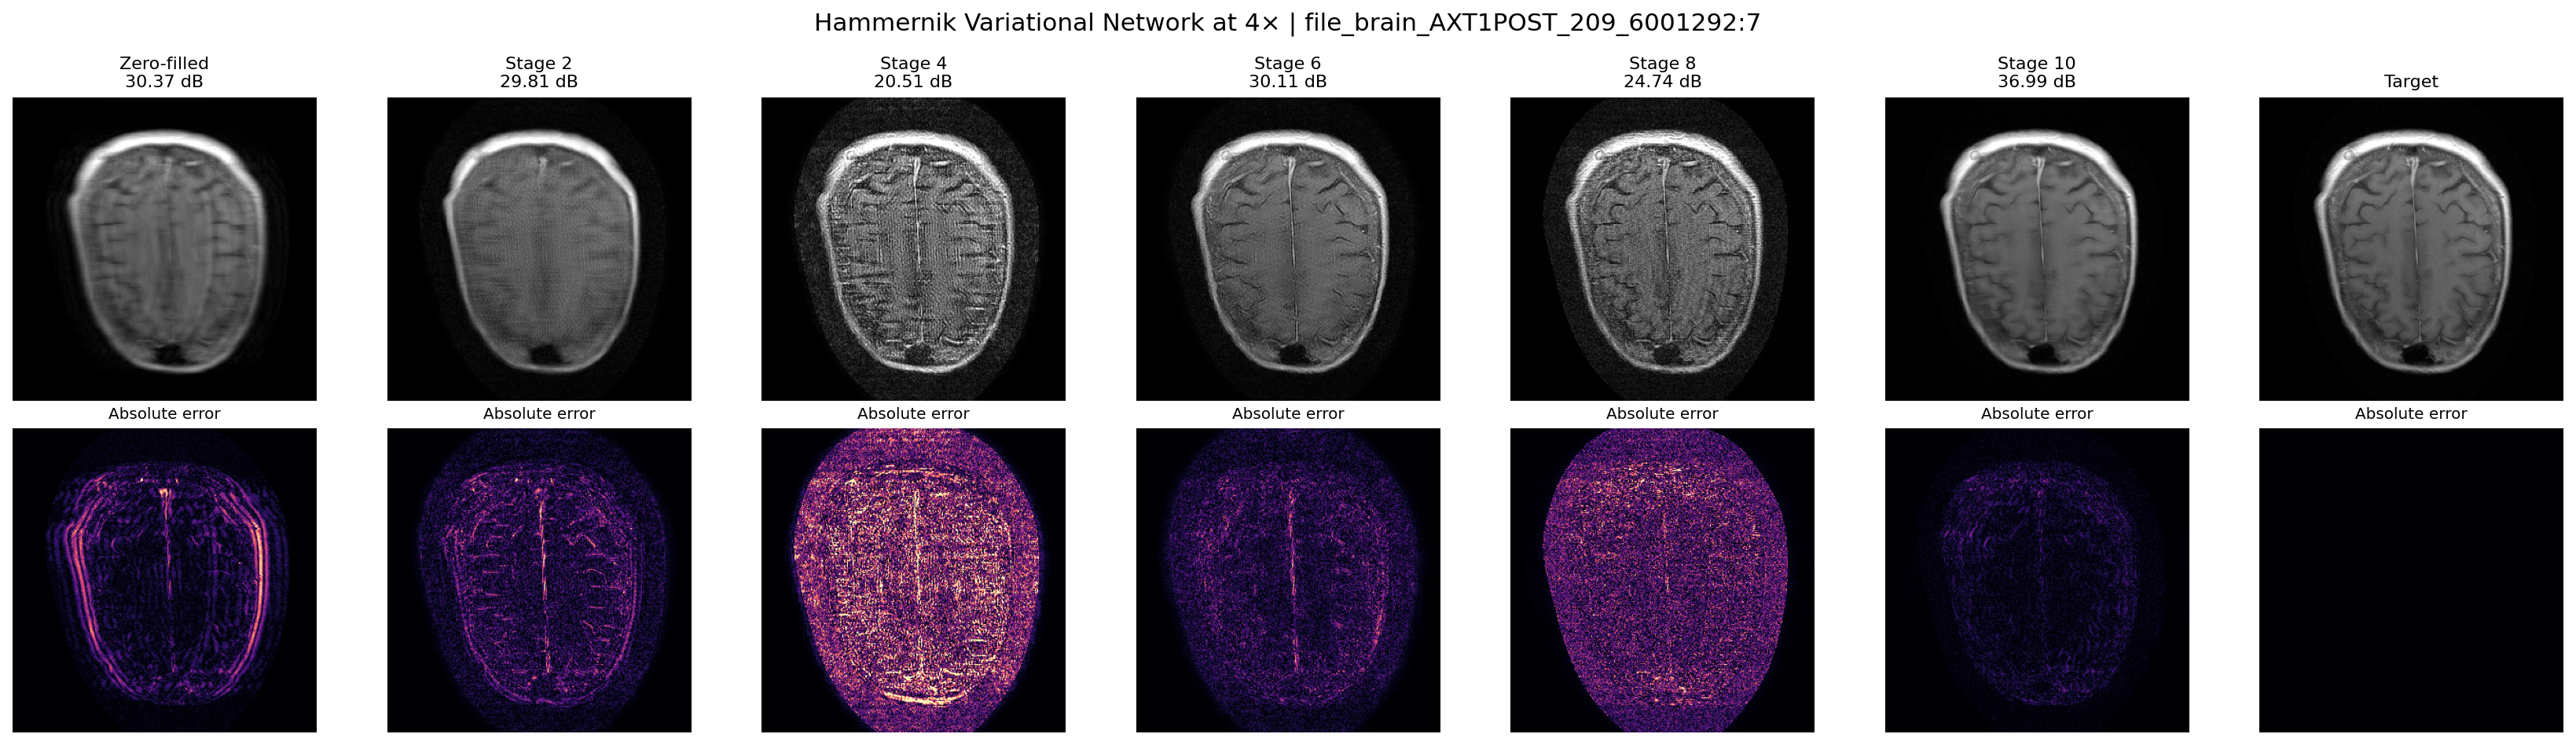

State,PSNR,SSIM,NMSE
Zero-filled,30.3685,0.8487,0.0266
Stage 2,29.8075,0.6774,0.0350
Stage 4,20.5112,0.4668,0.2983
Stage 6,30.1106,0.7197,0.0326
Stage 8,24.7362,0.5741,0.1100
Stage 10,36.9889,0.9364,0.0073


In [8]:
print(f"Representative sample: {progression['sample_id']} ({progression['selection_reason']})")
display(Image(filename=str(ROOT/'results/variational_network_evaluation/qualitative/stage_progression.png'), width=2400))
metric_rows = [{'State': name, 'PSNR': values['psnr'], 'SSIM': values['ssim'], 'NMSE': values['nmse']}
               for name, values in progression['metrics'].items()]
show_table(metric_rows, [(key, key) for key in metric_rows[0]])

## Interpretation

- Validation selected epoch 25 at 2× and 4× and epoch 40 at 6×; the final epoch was
  not automatically used for test reporting.
- VarNet improves PSNR, SSIM, and complex NMSE over zero-filled SENSE at every
  completed acceleration rate.
- Intermediate stages are not required to improve monotonically: the ten updates are
  jointly learned as one trajectory, and stage 10 is the reported reconstruction.
- The acquisition-specific table is retained for every rate because aggregate scores
  can hide different behavior across AXFLAIR and the two T1 groups.
- This is a faithful architecture/optimizer port, not an exact reproduction of the
  publication's knee-data experiment.
- Runtime values are descriptive single-pass measurements, not isolated benchmarks.

## Reproducibility artifacts

In [9]:
artifacts = []
for rate in RATES:
    selected = rate_selections[rate]
    rate_test_dir = RUNS[rate]/'evaluation/test'/f"step-{selected['checkpoint_step']:07d}"
    artifacts.extend([
        {'Rate':f'{rate}×','Artifact':'Checkpoint selection',
         'Path':str(RUNS[rate]/'evaluation/best_validation_checkpoint.json')},
        {'Rate':f'{rate}×','Artifact':'Test summary','Path':str(rate_test_dir/'summary.json')},
        {'Rate':f'{rate}×','Artifact':'Test slice metrics','Path':str(rate_test_dir/'slice_metrics.jsonl')},
        {'Rate':f'{rate}×','Artifact':'Training log','Path':str(RUNS[rate]/'train.log')},
    ])
artifacts.append({'Rate':'4×','Artifact':'Stage progression',
                  'Path':str(ROOT/'results/variational_network_evaluation/qualitative/stage_progression.png')})
show_table(artifacts, [('Rate','Rate'),('Artifact','Artifact'),('Path','Path')], precision=0)

Rate,Artifact,Path
2×,Checkpoint selection,/data/david_agyei/nyu-dataset/derived/hammernik_variational_network_2x_ipalm/evaluation/best_validation_checkpoint.json
2×,Test summary,/data/david_agyei/nyu-dataset/derived/hammernik_variational_network_2x_ipalm/evaluation/test/step-0004850/summary.json
2×,Test slice metrics,/data/david_agyei/nyu-dataset/derived/hammernik_variational_network_2x_ipalm/evaluation/test/step-0004850/slice_metrics.jsonl
2×,Training log,/data/david_agyei/nyu-dataset/derived/hammernik_variational_network_2x_ipalm/train.log
4×,Checkpoint selection,/data/david_agyei/nyu-dataset/derived/hammernik_variational_network_4x_ipalm/evaluation/best_validation_checkpoint.json
4×,Test summary,/data/david_agyei/nyu-dataset/derived/hammernik_variational_network_4x_ipalm/evaluation/test/step-0004850/summary.json
4×,Test slice metrics,/data/david_agyei/nyu-dataset/derived/hammernik_variational_network_4x_ipalm/evaluation/test/step-0004850/slice_metrics.jsonl
4×,Training log,/data/david_agyei/nyu-dataset/derived/hammernik_variational_network_4x_ipalm/train.log
6×,Checkpoint selection,/data/david_agyei/nyu-dataset/derived/hammernik_variational_network_6x_ipalm/evaluation/best_validation_checkpoint.json
6×,Test summary,/data/david_agyei/nyu-dataset/derived/hammernik_variational_network_6x_ipalm/evaluation/test/step-0007760/summary.json
